In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Part A: correlated outcomes (00 and 11)
qc_a = QuantumCircuit(2, 2)
qc_a.h(0)
qc_a.cx(0, 1)
qc_a.measure([0, 1], [0, 1])

# Part B: opposite outcomes (01 and 10), one extra X gate on qubit 1
qc_b = QuantumCircuit(2, 2)
qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)
qc_b.measure([0, 1], [0, 1])

print("Part A circuit"); print(qc_a.draw())
print("Part B circuit"); print(qc_b.draw())

Part A circuit
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Part B circuit
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 


In [4]:
print("PREDICTIONS (before running)")
print("-" * 55)
print("Part A (H, CNOT):")
print("  '00' and '11' will dominate, about 50% each.")
print("  '01' and '10' should not appear.\n")
print("Part B (H, CNOT, X on qubit 1):")
print("  '01' and '10' will dominate, about 50% each.")
print("  '00' and '11' should not appear.\n")
print("Will all four outcomes appear? No. In each circuit only two of the four")
print("outcomes appear, because the qubits are entangled and their results are linked.")
print("Each of those two outcomes is about 50% because the H gate makes the first")
print("qubit a fair coin, and the CNOT forces the second qubit to follow it.")

PREDICTIONS (before running)
-------------------------------------------------------
Part A (H, CNOT):
  '00' and '11' will dominate, about 50% each.
  '01' and '10' should not appear.

Part B (H, CNOT, X on qubit 1):
  '01' and '10' will dominate, about 50% each.
  '00' and '11' should not appear.

Will all four outcomes appear? No. In each circuit only two of the four
outcomes appear, because the qubits are entangled and their results are linked.
Each of those two outcomes is about 50% because the H gate makes the first
qubit a fair coin, and the CNOT forces the second qubit to follow it.


In [5]:
sim = AerSimulator()
shots = 100

def run_circuit(qc):
    compiled = transpile(qc, sim)
    result = sim.run(compiled, shots=shots).result()
    return result.get_counts()

counts_a = run_circuit(qc_a)
counts_b = run_circuit(qc_b)

print("Part A results:", counts_a)
print("Part B results:", counts_b)

Part A results: {'11': 53, '00': 47}
Part B results: {'01': 41, '10': 59}


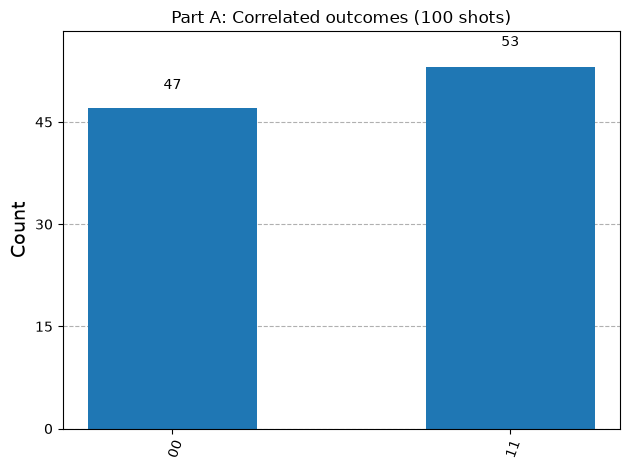

In [6]:
plot_histogram(counts_a, title="Part A: Correlated outcomes (100 shots)")

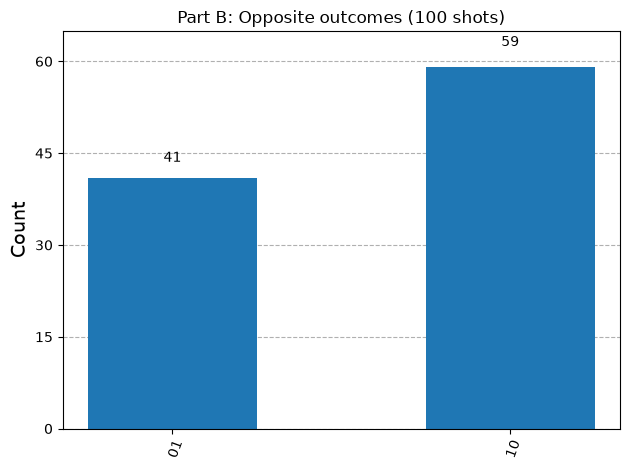

In [7]:
plot_histogram(counts_b, title="Part B: Opposite outcomes (100 shots)")

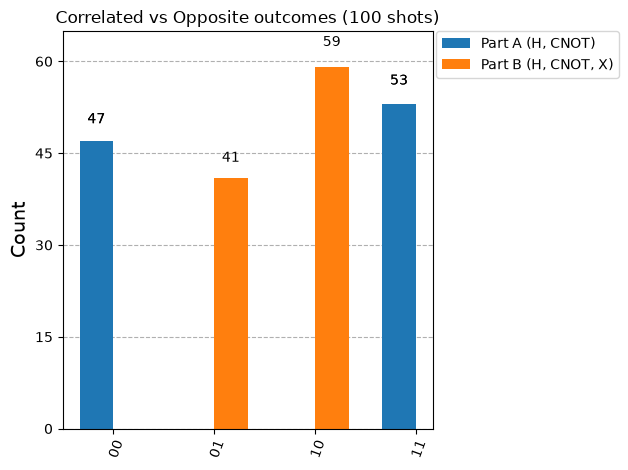

In [8]:
plot_histogram([counts_a, counts_b],
               legend=["Part A (H, CNOT)", "Part B (H, CNOT, X)"],
               title="Correlated vs Opposite outcomes (100 shots)")

In [9]:
print("COMPARISON: PREDICTIONS vs ACTUAL RESULTS")
print("-" * 60)
print(f"Part A | Predicted: ~50% '00', ~50% '11' | Actual: {counts_a}")
print(f"Part B | Predicted: ~50% '01', ~50% '10' | Actual: {counts_b}")

print("\nWhich outcomes are dominant in Part A?")
print("  '00' and '11'. The two qubits always give the same result.")

print("\nWhich outcomes are dominant in Part B?")
print("  '01' and '10'. The two qubits always give different results.")

print("\nWhat changed between the two circuits?")
print("  One X gate was added on qubit 1, after the CNOT and before measurement.")

print("\nWhy did the measurement relationship change?")
print("  The H gate puts qubit 0 in superposition, and the CNOT entangles the qubits,")
print("  producing (|00> + |11>)/sqrt(2). The qubits always match.")
print("  The X gate flips qubit 1 in every outcome, turning the state into")
print("  (|01> + |10>)/sqrt(2). The qubits are still perfectly correlated,")
print("  but now they always differ. So the X gate acts as a switch between")
print("  'same' and 'opposite' outcomes.")

COMPARISON: PREDICTIONS vs ACTUAL RESULTS
------------------------------------------------------------
Part A | Predicted: ~50% '00', ~50% '11' | Actual: {'11': 53, '00': 47}
Part B | Predicted: ~50% '01', ~50% '10' | Actual: {'01': 41, '10': 59}

Which outcomes are dominant in Part A?
  '00' and '11'. The two qubits always give the same result.

Which outcomes are dominant in Part B?
  '01' and '10'. The two qubits always give different results.

What changed between the two circuits?
  One X gate was added on qubit 1, after the CNOT and before measurement.

Why did the measurement relationship change?
  The H gate puts qubit 0 in superposition, and the CNOT entangles the qubits,
  producing (|00> + |11>)/sqrt(2). The qubits always match.
  The X gate flips qubit 1 in every outcome, turning the state into
  (|01> + |10>)/sqrt(2). The qubits are still perfectly correlated,
  but now they always differ. So the X gate acts as a switch between
  'same' and 'opposite' outcomes.
